# MobileNetV3-Small + GRU32: Wide-Crop Experiment

A compact temporal crash-prediction model using four frames, a **224 x 384** crop, and fine-tuning of the final two encoder blocks.

**Selected checkpoint:** seed 42, epoch 7, without EMA. This is the contributor's selected candidate for team comparison, not the team's final model selection.

| Dataset | Videos | Binary-F1 | Macro-F1 | Accuracy |
|---|---:|---:|---:|---:|
| Validation | 300 | 75.25% | 75.00% | 75.00% |
| Public test | 667 | 69.87% | 68.94% | 68.97% |

The checkpoint was selected using validation Binary-F1. Validation and public test are separate datasets.

This notebook reads the existing checkpoint and JSON results in `NexarCrashPrediction/`

Default execution loads the saved model and displays recorded results


In [ ]:
from pathlib import Path
import sys, json, hashlib
import torch

PROJECT_DIR = None  # Optional: path to the NexarCrashPrediction folder.
candidates = [Path.cwd(), Path.cwd()/'NexarCrashPrediction', Path.cwd()/'crash-detection-vision'/'NexarCrashPrediction']
candidates += [p/'NexarCrashPrediction' for p in list(Path.cwd().parents)[:3]]
ROOT = Path(PROJECT_DIR).resolve() if PROJECT_DIR else next((p.resolve() for p in candidates if (p/'nexar_pipeline.py').is_file() and (p/'model/metadata.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Set PROJECT_DIR to the NexarCrashPrediction folder.')
sys.path.insert(0, str(ROOT))
import nexar_pipeline as pipeline
if Path(pipeline.__file__).resolve() != ROOT/'nexar_pipeline.py':
    raise RuntimeError('Restart the kernel: another nexar_pipeline module is loaded.')

metadata = json.loads((ROOT/'model/metadata.json').read_text(encoding='utf-8'))
checkpoint_path = ROOT/'model/best_model.pt'
if hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() != metadata['checkpoint_sha256']:
    raise ValueError('Checkpoint checksum mismatch.')
# Normalize line endings so Git checkouts on Windows and Linux verify identically.
pipeline_bytes = (ROOT/'nexar_pipeline.py').read_bytes().replace(b'\r\n', b'\n')
if hashlib.sha256(pipeline_bytes).hexdigest() != metadata['pipeline_sha256']:
    raise ValueError('Pipeline checksum mismatch.')
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
settings = json.loads((ROOT/'model/settings.json').read_text(encoding='utf-8'))
if checkpoint['settings'] != settings or checkpoint['epoch'] != metadata['selected_epoch']:
    raise ValueError('Checkpoint metadata mismatch.')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = pipeline.SmallTemporalModel(weights=None).to(device)
model.load_state_dict(checkpoint['model'], strict=True)
model.eval()
del checkpoint

print('Device:', device)
print('Selected model: seed42 / epoch7 / 224x384 / no EMA')
metrics = json.loads((ROOT/'results/metrics.json').read_text(encoding='utf-8'))
for split in ('validation','public'):
    m = metrics[split]
    print(f"{split} ({m['count']} videos) | Binary-F1 {m['binary_f1']:.2%} | Macro-F1 {m['macro_f1']:.2%} | Accuracy {m['accuracy']:.2%}")


## Single-video prediction

Set `VIDEO_PATH` and run the next cell. Four chronological frames are sampled over the final 1.5 seconds of the video. Neither a class label nor an event timestamp is required.


In [ ]:
@torch.inference_mode()
def predict_video(video_path, model, device):
    path = Path(video_path).resolve()
    record = pipeline.make_record(path, path.stem, 0, 'inference', event_time=None)
    dataset = pipeline.FourFrameDataset([record], training=False, cache=False)
    x = dataset[0][0].unsqueeze(0).to(device)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
        logits = model(x)
    prediction = int(logits.argmax(1).item())
    return dict(video_id=path.stem, prediction=prediction, label='collision_or_near_miss' if prediction else 'normal_driving', probability_positive=float(logits.float().softmax(1)[0, 1].item()), frame_seconds=record['actual_seconds'], crop_size=[224, 384])

VIDEO_PATH = None  # Example: r'D:\videos\example.mp4'
if VIDEO_PATH:
    prediction = predict_video(VIDEO_PATH, model, device)
    print(json.dumps(prediction, indent=2))
else:
    print('Set VIDEO_PATH to run one prediction. No videos evaluated.')


## Recorded training history

Epochs 1-2 train the temporal head. Starting at epoch 3, the final two CNN blocks are also fine-tuned while BatchNorm running statistics remain fixed. Epoch 7 was selected, and early stopping ended the run after epoch 10.

The following cells read the saved history only. Training metrics were recorded with augmentation and dropout active; validation metrics were recorded in evaluation mode.


In [3]:
history = json.loads((ROOT/'results/history.json').read_text(encoding='utf-8'))
print('Epoch | Stage | Train Binary-F1 | Val Binary-F1 | Val Macro-F1 | Val Accuracy')
for row in history:
    t, v = row['train'], row['validation']
    print(f"{row['epoch']:>5} | {row['stage']:<13} | {t['binary_f1']:.2%} | {v['binary_f1']:.2%} | {v['macro_f1']:.2%} | {v['accuracy']:.2%}")


Epoch | Stage | Train Binary-F1 | Val Binary-F1 | Val Macro-F1 | Val Accuracy
    1 | temporal_head | 64.39% | 58.17% | 64.04% | 65.00%
    2 | temporal_head | 72.52% | 72.31% | 71.65% | 71.67%
    3 | encoder_tail  | 73.58% | 73.68% | 73.33% | 73.33%
    4 | encoder_tail  | 74.71% | 72.73% | 73.00% | 73.00%
    5 | encoder_tail  | 75.44% | 69.69% | 70.95% | 71.00%
    6 | encoder_tail  | 75.21% | 74.83% | 74.67% | 74.67%
    7 | encoder_tail  | 75.02% | 75.25% | 75.00% | 75.00%
    8 | encoder_tail  | 77.29% | 75.08% | 75.00% | 75.00%
    9 | encoder_tail  | 76.68% | 74.25% | 74.33% | 74.33%
   10 | encoder_tail  | 76.61% | 75.08% | 75.00% | 75.00%


## Training and validation curves

Loss and accuracy over the **10 epochs actually completed**. Red represents training and green represents validation. Values are plotted directly from the recorded history, without smoothing or interpolation. The accuracy panel shows accuracy, not Binary-F1.


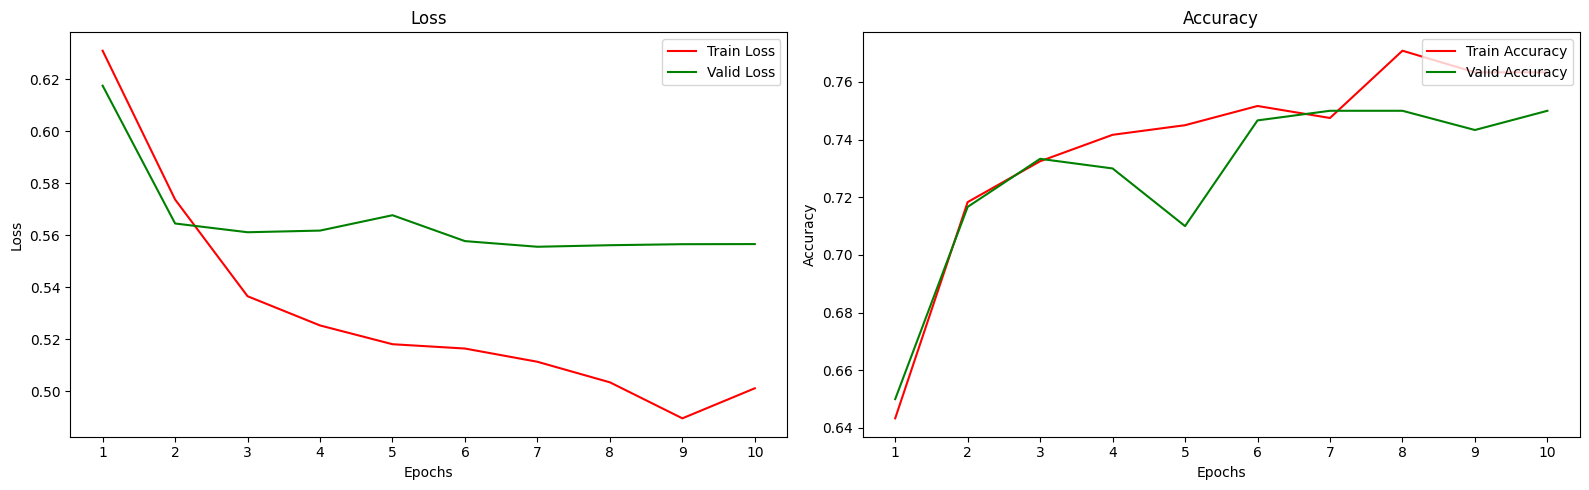

In [4]:
import matplotlib.pyplot as plt

history = json.loads((ROOT / "results" / "history.json").read_text(encoding="utf-8"))
epochs = [row["epoch"] for row in history]
train_loss = [row["train"]["loss"] for row in history]
valid_loss = [row["validation"]["loss"] for row in history]
train_accuracy = [row["train"]["accuracy"] for row in history]
valid_accuracy = [row["validation"]["accuracy"] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(epochs, train_loss, color="red", label="Train Loss")
axes[0].plot(epochs, valid_loss, color="green", label="Valid Loss")
axes[0].set_title("Loss")
axes[0].set_ylabel("Loss")

axes[1].plot(epochs, train_accuracy, color="red", label="Train Accuracy")
axes[1].plot(epochs, valid_accuracy, color="green", label="Valid Accuracy")
axes[1].set_title("Accuracy")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.set_xlabel("Epochs")
    ax.set_xticks(epochs)
    ax.legend(loc="upper right")

fig.tight_layout()
plt.show()
